<a href="https://colab.research.google.com/github/davidrpugh/data-analytics-with-polars/blob/main/ch16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 16: Visualizing Data

In [26]:
%pip install --upgrade "polars==2.1.*"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.5/33.5 MB 12.3 MB/s  0:00:02


In [11]:
import pathlib
import urllib

import polars as pl
pl.__version__

'2.1.0'

In [51]:
from google.colab import output
output.enable_custom_widget_manager()

In [12]:
DAYS = range(1, 31 + 1)

CITIBIKE_DIR = pathlib.Path("sample_data/citibike")
BASE_URL = "https://github.com/davidrpugh/data-analytics-with-polars/raw/refs/heads/main/data/citibike"


def download_citibike_files(days) -> list[str]:
    """Download the daily Parquet files (if needed) and return their paths."""
    CITIBIKE_DIR.mkdir(parents=True, exist_ok=True)
    paths = []
    for day in days:
        name = f"trips-2024-03-{day:02d}.parquet"
        path = CITIBIKE_DIR / name
        if not path.exists():
            temporary = path.with_suffix(".tmp")
            urllib.request.urlretrieve(f"{BASE_URL}/{name}", temporary)
            temporary.rename(path)
        print(f"{name}: {path.stat().st_size / 1e6:.1f} MB")
        paths.append(str(path))
    return paths


CITIBIKE_FILES = download_citibike_files(DAYS)

trips-2024-03-01.parquet: 3.2 MB
trips-2024-03-02.parquet: 1.1 MB
trips-2024-03-03.parquet: 4.1 MB
trips-2024-03-04.parquet: 3.5 MB
trips-2024-03-05.parquet: 1.9 MB
trips-2024-03-06.parquet: 2.0 MB
trips-2024-03-07.parquet: 3.4 MB
trips-2024-03-08.parquet: 3.8 MB
trips-2024-03-09.parquet: 1.6 MB
trips-2024-03-10.parquet: 2.3 MB
trips-2024-03-11.parquet: 3.0 MB
trips-2024-03-12.parquet: 4.3 MB
trips-2024-03-13.parquet: 4.4 MB
trips-2024-03-14.parquet: 4.9 MB
trips-2024-03-15.parquet: 4.5 MB
trips-2024-03-16.parquet: 4.2 MB
trips-2024-03-17.parquet: 3.7 MB
trips-2024-03-18.parquet: 3.4 MB
trips-2024-03-19.parquet: 3.4 MB
trips-2024-03-20.parquet: 3.3 MB
trips-2024-03-21.parquet: 3.1 MB
trips-2024-03-22.parquet: 3.2 MB
trips-2024-03-23.parquet: 0.9 MB
trips-2024-03-24.parquet: 2.7 MB
trips-2024-03-25.parquet: 3.4 MB
trips-2024-03-26.parquet: 3.8 MB
trips-2024-03-27.parquet: 3.5 MB
trips-2024-03-28.parquet: 2.1 MB
trips-2024-03-29.parquet: 3.6 MB
trips-2024-03-30.parquet: 3.5 MB
trips-2024

## NYC Bike Trips

In [13]:
trips = pl.read_parquet("sample_data/citibike/trips-2024-03-*.parquet")

In [14]:
print(trips[:, :4])
print(trips[:, 4:7])
print(trips[:, 7:11])
print(trips[:, 11:])

shape: (2_638_971, 4)
┌───────────┬────────────┬─────────────────────────┬─────────────────────────┐
│ bike_type ┆ rider_type ┆ datetime_start          ┆ datetime_end            │
│ ---       ┆ ---        ┆ ---                     ┆ ---                     │
│ cat       ┆ cat        ┆ datetime[μs]            ┆ datetime[μs]            │
╞═══════════╪════════════╪═════════════════════════╪═════════════════════════╡
│ electric  ┆ member     ┆ 2024-03-01 00:00:02.490 ┆ 2024-03-01 00:27:39.295 │
│ electric  ┆ member     ┆ 2024-03-01 00:00:04.120 ┆ 2024-03-01 00:09:29.384 │
│ electric  ┆ casual     ┆ 2024-03-01 00:00:05.209 ┆ 2024-03-01 00:03:34.692 │
│ classic   ┆ member     ┆ 2024-03-01 00:00:05.259 ┆ 2024-03-01 00:31:02.219 │
│ electric  ┆ member     ┆ 2024-03-01 00:00:09.837 ┆ 2024-03-01 00:11:42.320 │
│ …         ┆ …          ┆ …                       ┆ …                       │
│ classic   ┆ member     ┆ 2024-03-31 23:55:29.002 ┆ 2024-03-31 23:57:10.376 │
│ classic   ┆ member     ┆ 202

## Built-In Plotting with Altair

### Introducing Altair

In [ ]:
%pip install --upgrade "vegafusion[embed]>=1.5.0" "vl-convert-python>=1.6.0"

In [8]:
import altair as alt

### Methods in the Plot Namespaces

### Plotting DataFrames

In [15]:
trips_speed = trips.select(
    pl.col("distance"),
    pl.col("duration").dt.total_seconds() / 3600,
    pl.col("bike_type"),
).with_columns(speed=pl.col("distance") / pl.col("duration"))

trips_speed

distance,duration,bike_type,speed
f64,f64,cat,f64
4.842569,0.46,"""electric""",10.527324
2.659582,0.156944,"""electric""",16.94601
0.398795,0.058056,"""electric""",6.869194
5.09153,0.515556,"""classic""",9.875812
3.08728,0.192222,"""electric""",16.060992
…,…,…,…
0.272175,0.028056,"""classic""",9.701291
0.492269,0.058333,"""classic""",8.438897
0.406138,0.029444,"""classic""",13.793378


In [16]:
# This raises a MaxRowsError:
trips_speed.plot.scatter(
   x="distance",
   y="duration",
   color="bike_type:N",
)

MaxRowsError: The number of rows in your dataset is greater than the maximum allowed (5000).

Try enabling the VegaFusion data transformer which raises this limit by pre-evaluating data
transformations in Python.
    >> import altair as alt
    >> alt.data_transformers.enable("vegafusion")

Or, see https://altair-viz.github.io/user_guide/large_datasets.html for additional information
on how to plot large datasets.

alt.Chart(...)

In [17]:
trips_speed = (
    trips.filter(pl.col("station_start") == "W 70 St & Amsterdam Ave")
    .select(
        pl.col("distance"),
        pl.col("duration").dt.total_seconds() / 3600,
        pl.col("bike_type"),
    )
    .with_columns(speed=pl.col("distance") / pl.col("duration"))
)

trips_speed

distance,duration,bike_type,speed
f64,f64,cat,f64
0.596344,0.039167,"""electric""",15.225797
1.134568,0.153611,"""classic""",7.385977
4.586869,0.492778,"""electric""",9.30819
0.839622,0.046111,"""electric""",18.208666
0.351954,0.027778,"""electric""",12.670335
…,…,…,…
2.850176,0.172778,"""electric""",16.496196
0.590008,0.060833,"""classic""",9.698761
1.821509,0.133611,"""electric""",13.632919


In [18]:
trips_speed.plot.scatter(
    x="distance",
    y="duration",
    color="bike_type:N",
)

alt.Chart(...)

### Too Large to Handle

In [19]:
import altair as alt

alt.data_transformers.disable_max_rows()

DataTransformerRegistry.enable('default')

In [20]:
alt.data_transformers.enable("vegafusion")

DataTransformerRegistry.enable('vegafusion')

In [21]:
trips_type_counts = trips.group_by("rider_type", "bike_type").len()
trips_type_counts

rider_type,bike_type,len
cat,cat,u32
"""member""","""electric""",1412598
"""casual""","""electric""",294679
"""member""","""classic""",811168
"""casual""","""classic""",120526


In [27]:
from IPython.display import display

chart = trips_type_counts.plot.bar(
    x="rider_type", y="len", fill="bike_type:N"
).properties(
    width=300,
)
display(chart)

alt.Chart(...)

### Plotting Series

In [28]:
trips_speed["distance"].plot.kde()

alt.Chart(...)

In [29]:
trips_speed["distance"].plot.hist()

alt.Chart(...)

In [30]:
trips_hour_num_speed = (
    trips.sort("datetime_start")
    .group_by_dynamic("datetime_start", every="1h")
    .agg(
        num_trips=pl.len(),
        speed=(
            pl.col("distance") / (pl.col("duration").dt.total_seconds() / 3600)
        ).median(),
    )
    .filter(pl.col("datetime_start") > pl.date(2024, 3, 26))
)

trips_hour_num_speed

datetime_start,num_trips,speed
datetime[μs],u32,f64
2024-03-26 01:00:00,295,13.813106
2024-03-26 02:00:00,181,14.317642
2024-03-26 03:00:00,119,13.150871
2024-03-26 04:00:00,222,14.239003
2024-03-26 05:00:00,878,13.966456
…,…,…
2024-03-31 19:00:00,5170,10.692934
2024-03-31 20:00:00,3640,11.057322
2024-03-31 21:00:00,2813,11.429875


In [31]:
trips_hour_num_speed.plot.line(x="datetime_start", y="num_trips")

alt.Chart(...)

## pandas-Like Plotting with hvPlot

In [33]:
%pip install --upgrade "hvplot"

### Introducing hvPlot

In [34]:
import hvplot.polars

### A First Plot

In [35]:
trips_speed.hvplot.scatter(
    x="distance",
    y="duration",
    color="bike_type",
    xlabel="distance (km)",
    ylabel="duration (h)",
    ylim=(0, 2),
)

:Scatter   [distance]   (duration,bike_type)

### Methods in the hvPlot Namespace

### pandas as Backup

In [36]:
trips_per_day_hour = (
    trips.sort("datetime_start")
    .group_by_dynamic("datetime_start", every="1h")
    .agg(pl.len())
)

In [37]:
# This raises a ValueError:
trips_per_day_hour.hvplot.heatmap(
    x="datetime_start.hour", y="datetime_start.day", C="len", cmap="reds"
)

ValueError: 'datetime_start.hour' is not in list

In [38]:
import hvplot.pandas

trips_per_day_hour.to_pandas().hvplot.heatmap(
    x="datetime_start.hour", y="datetime_start.day", C="len", cmap="reds"
)

:HeatMap   [datetime_start.hour,datetime_start.day]   (len)

### Manual Transformations

In [39]:
trips_type_counts.hvplot.bar(
    x="rider_type",
    y="len",
    by="bike_type",
    ylabel="count",
    stacked=True,
    color=["orange", "green"],
)

:Bars   [rider_type,bike_type]   (len)

### Changing the Plotting Backend

In [40]:
import hvplot

hvplot.extension("matplotlib")

:Bars   [rider_type,bike_type]   (len)
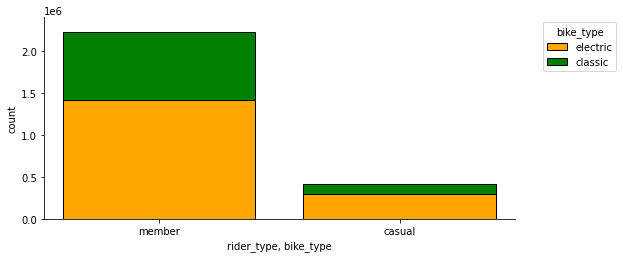

In [41]:
trips_type_counts.hvplot.bar(
    x="rider_type",
    y="len",
    by="bike_type",
    ylabel="count",
    stacked=True,
    color=["orange", "green"],
)

In [42]:
hvplot.extension("bokeh")

### Plotting Points on a Map

In [49]:
%pip install datashader geoviews jupyter_bokeh

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 6.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 7.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 9.2 MB/s  0:00:00
  Attempting uninstall: widgetsnbextension
    Found existing installation: widgetsnbextension 3.6.10
    Uninstalling widgetsnbextension-3.6.10:
      Successfully uninstalled widgetsnbextension-3.6.10
  Attempting uninstall: ipywidgets
    Found existing installation: ipywidgets 7.7.1
    Uninstalling ipywidgets-7.7.1:
      Successfully uninstalled ipywidgets-7.7.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [jupyter_bokeh]


In [52]:
trips.hvplot.points(
    x="lon_start",
    y="lat_start",
    datashade=True,
    geo=True,
    tiles="CartoLight",
    width=800,
    height=600,
)

BokehModel(combine_events=True, render_bundle={'docs_json': {'a248d2b0-ab5a-4a60-85f7-de908a6bc63b': {'version…

### Composing Plots

In [53]:
(
    trips_hour_num_speed.hvplot.line(x="datetime_start", y="num_trips")
    + trips_hour_num_speed.hvplot.line(x="datetime_start", y="speed")
).cols(
    1
)

:Layout
   .Curve.I  :Curve   [datetime_start]   (num_trips)
   .Curve.II :Curve   [datetime_start]   (speed)

In [54]:
(
    trips_hour_num_speed.hvplot.line(x="datetime_start", y="num_trips")
    * trips_hour_num_speed.filter(pl.col("num_trips") > 9000).hvplot.scatter(
        x="datetime_start", y="num_trips", c="red", s=50
    )
)

:Overlay
   .Curve.I   :Curve   [datetime_start]   (num_trips)
   .Scatter.I :Scatter   [datetime_start]   (num_trips)

### Adding Interactive Widgets

In [55]:
trips_per_hour = (
    trips.sort("datetime_start")
    .group_by_dynamic("datetime_start", group_by="borough_start", every="1h")
    .agg(pl.len())
    .with_columns(date=pl.col("datetime_start").dt.date())
)
trips_per_hour

borough_start,datetime_start,len,date
str,datetime[μs],u32,date
"""Bronx""",2024-03-01 00:00:00,43,2024-03-01
"""Bronx""",2024-03-01 01:00:00,14,2024-03-01
"""Bronx""",2024-03-01 02:00:00,17,2024-03-01
"""Bronx""",2024-03-01 03:00:00,6,2024-03-01
"""Bronx""",2024-03-01 04:00:00,10,2024-03-01
…,…,…,…
"""Manhattan""",2024-03-31 19:00:00,3113,2024-03-31
"""Manhattan""",2024-03-31 20:00:00,2184,2024-03-31
"""Manhattan""",2024-03-31 21:00:00,1668,2024-03-31


In [56]:
trips_per_hour.hvplot.line(
    x="datetime_start",
    by="borough_start",
    groupby="date",
    widget_location="left_top",
)

AttributeRemovedError: `NUMERIC_DTYPES` was deprecated in version 1.0.0. Define your own data type groups or use the `polars.selectors` module for selecting columns of a certain data type.

## Publication-Quality Graphics with plotnine

### Introducing plotnine

In [57]:
from plotnine import *

### Plots for Exploration

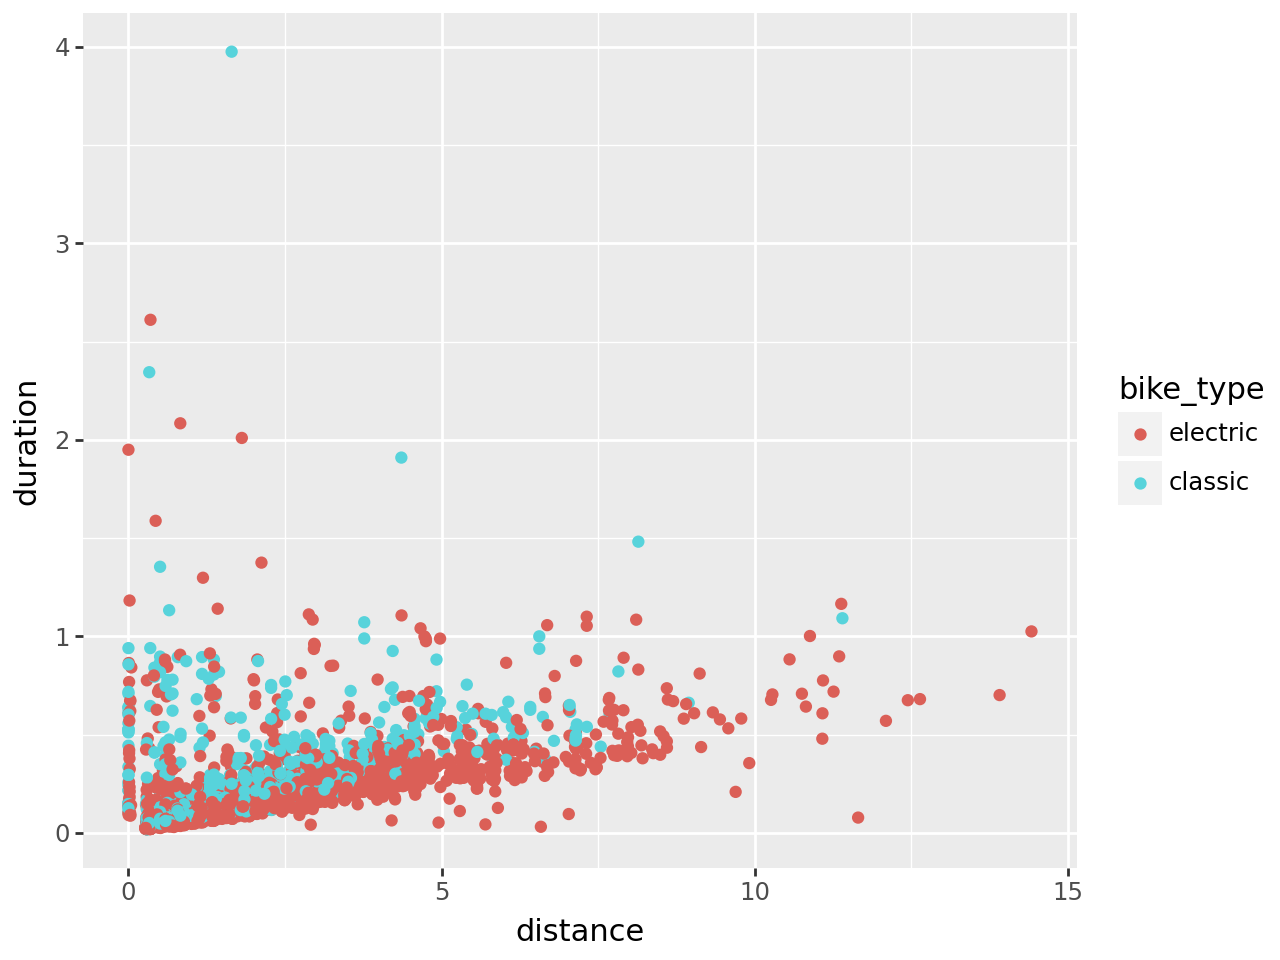

In [58]:
(
    ggplot(trips_speed, aes(x="distance", y="duration", color="bike_type"))
    + geom_point()
)

/usr/local/lib/python3.13/dist-packages/plotnine/stats/stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 72'. Pick better value with 'binwidth'.


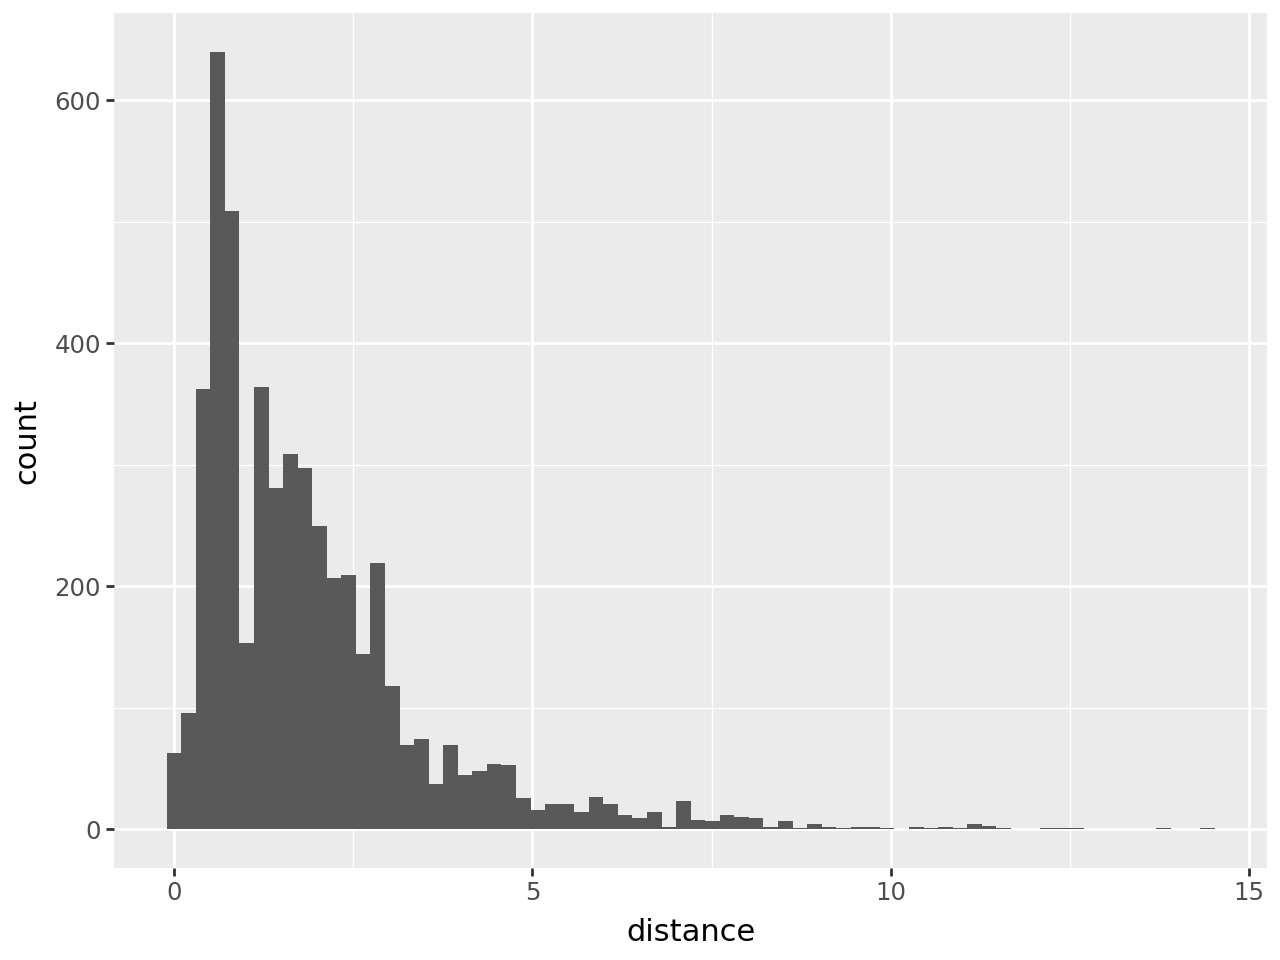

In [59]:
ggplot(trips_speed, aes(x="distance")) + geom_histogram()

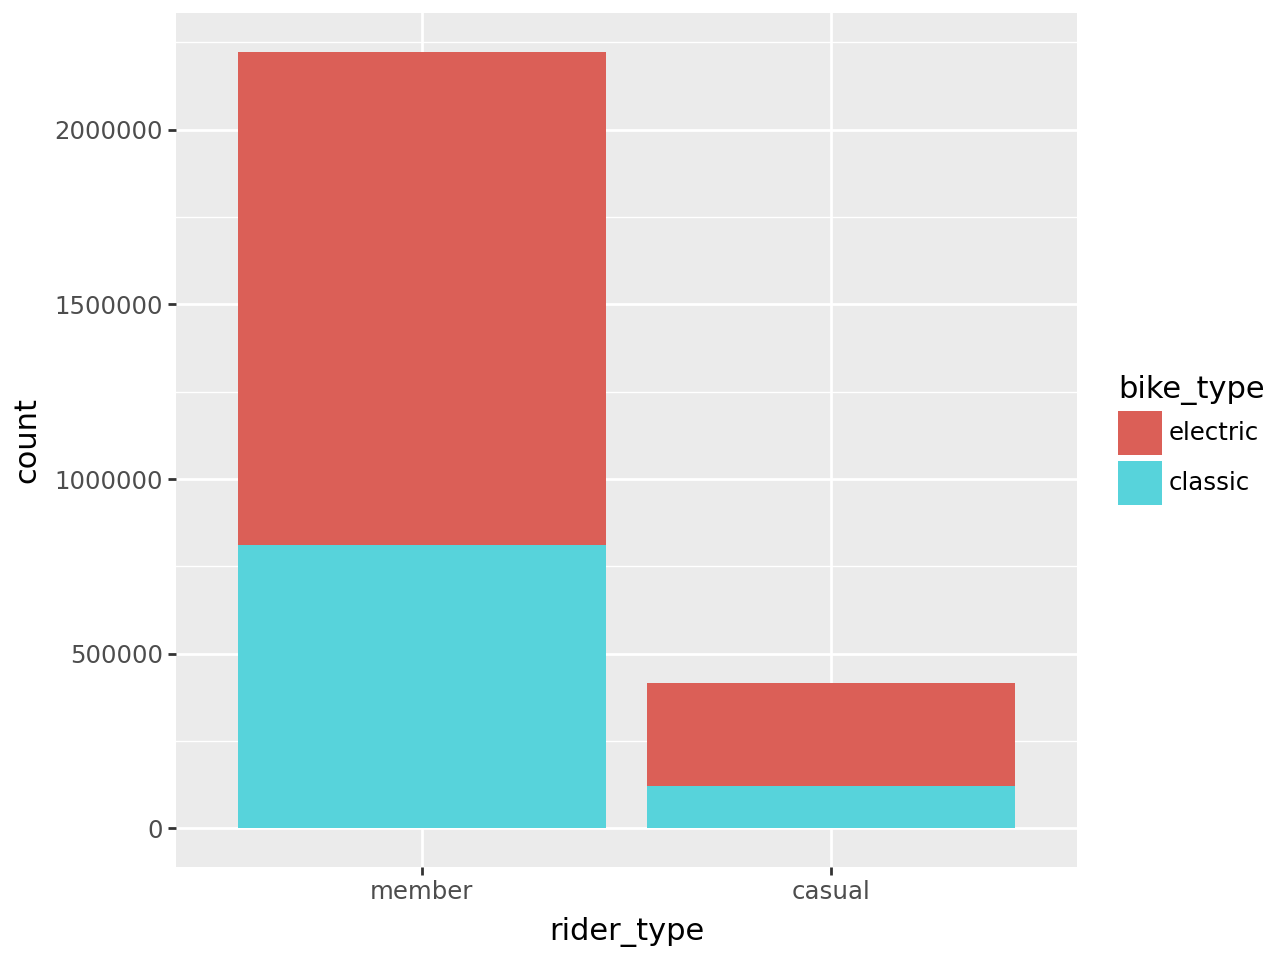

In [60]:
ggplot(trips, aes(x="rider_type", fill="bike_type")) + geom_bar()

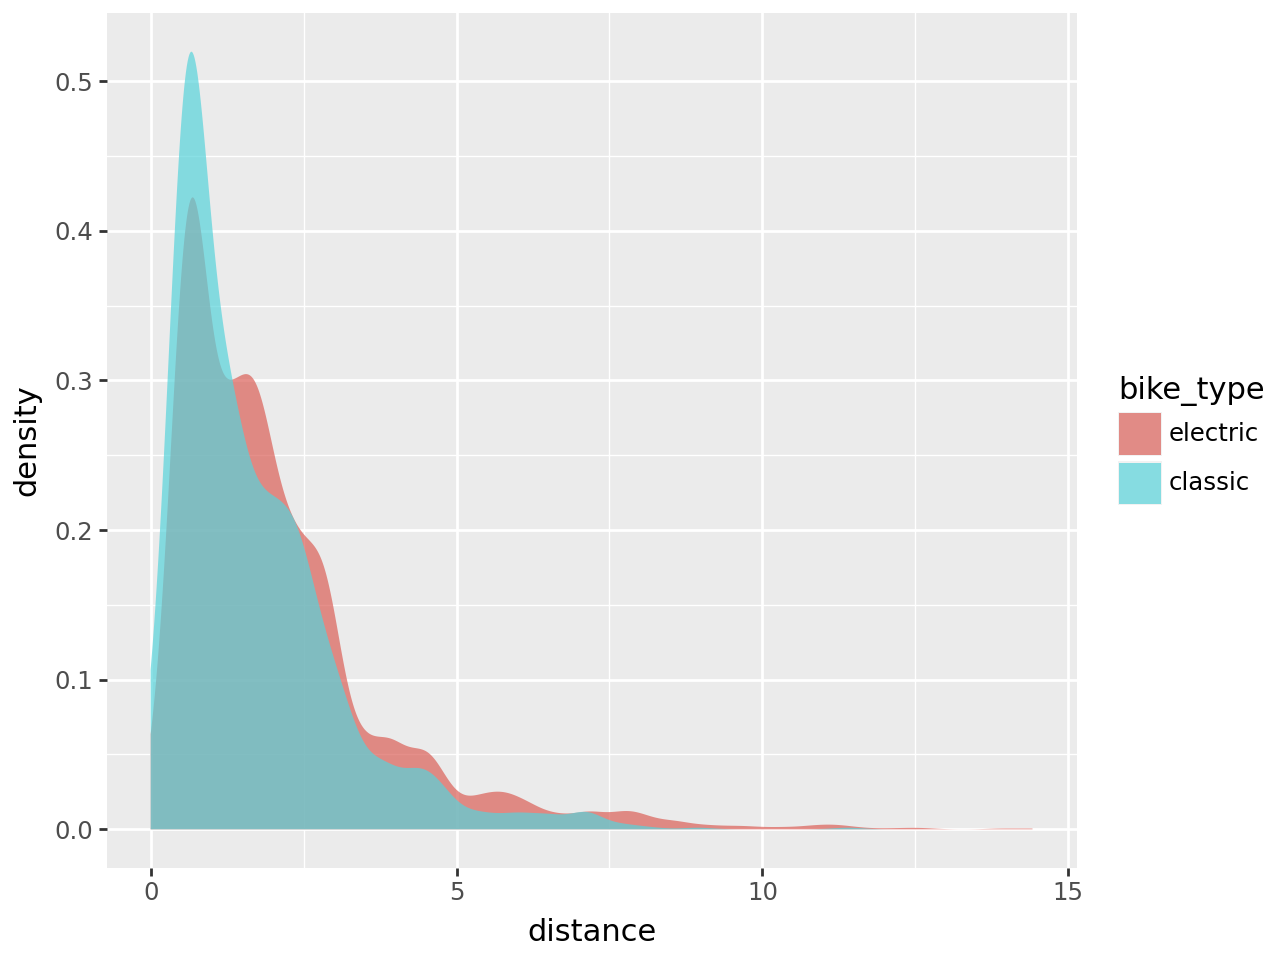

In [61]:
ggplot(trips_speed, aes(x="distance", fill="bike_type")) + geom_density(
    alpha=0.7, color="none"
)

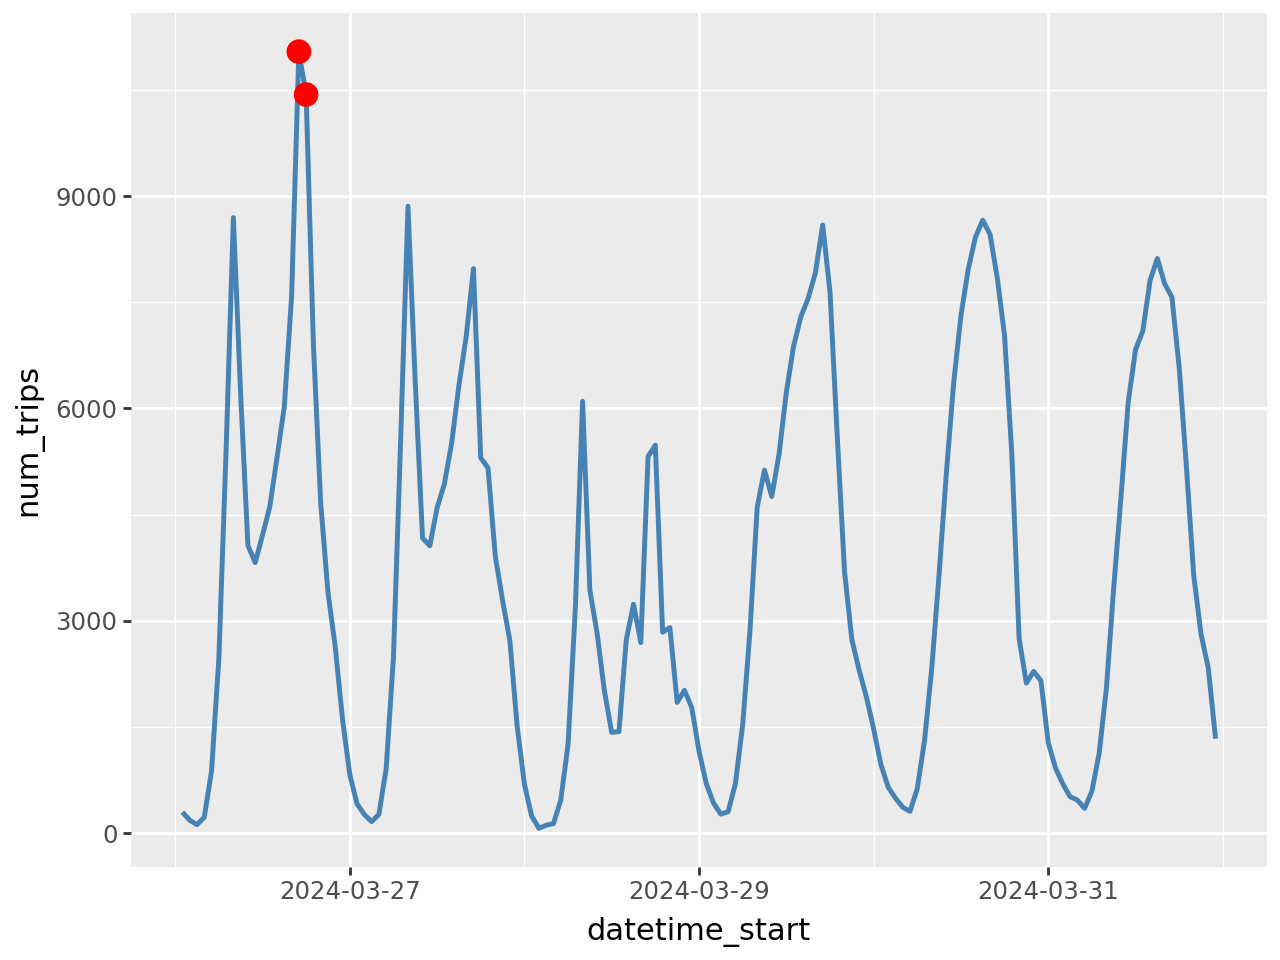

In [62]:
(
    ggplot(trips_hour_num_speed, aes(x="datetime_start", y="num_trips"))
    + geom_line(size=1, color="steelblue")
    + geom_point(
        data=trips_hour_num_speed.filter(pl.col("num_trips") > 9000),
        color="red",
        size=4,
    )
)

### Plots for Communication

In [63]:
trips_speed = (
    trips.group_by("neighborhood_start", "neighborhood_end")
    .agg(
        pl.col("duration").dt.total_seconds().median() / 60,
        pl.col("distance").median(),
        pl.col("borough_start").first(),
        pl.col("borough_end").first(),
        pl.len(),
    )
    .filter(
        (pl.col("len") > 30)
        & (pl.col("distance") > 0.2)
        & (pl.col("neighborhood_start") != pl.col("neighborhood_end")),
    )
    .with_columns(speed=pl.col("distance") / pl.col("duration"))
    .sort("borough_start")
)
trips_speed

neighborhood_start,neighborhood_end,duration,distance,borough_start,borough_end,len,speed
str,str,f64,f64,str,str,u32,f64
"""Belmont""","""Concourse Village""",15.116667,3.857727,"""Bronx""","""Bronx""",63,0.255197
"""Hunts Point""","""Mott Haven""",10.308333,2.166842,"""Bronx""","""Bronx""",44,0.210203
"""Concourse Village""","""Mount Eden""",7.091667,1.208237,"""Bronx""","""Bronx""",162,0.170374
"""Mott Haven""","""Morris Heights""",16.875,3.909558,"""Bronx""","""Bronx""",74,0.231678
"""Concourse Village""","""Midtown""",34.316667,9.668859,"""Bronx""","""Manhattan""",37,0.281754
…,…,…,…,…,…,…,…
"""Corona""","""East Elmhurst""",10.4,2.066131,"""Queens""","""Queens""",174,0.198666
"""Sunnyside""","""Midtown""",19.9,4.787756,"""Queens""","""Manhattan""",309,0.240591
"""Ditmars Steinway""","""East Elmhurst""",11.133333,2.241194,"""Queens""","""Queens""",259,0.201305


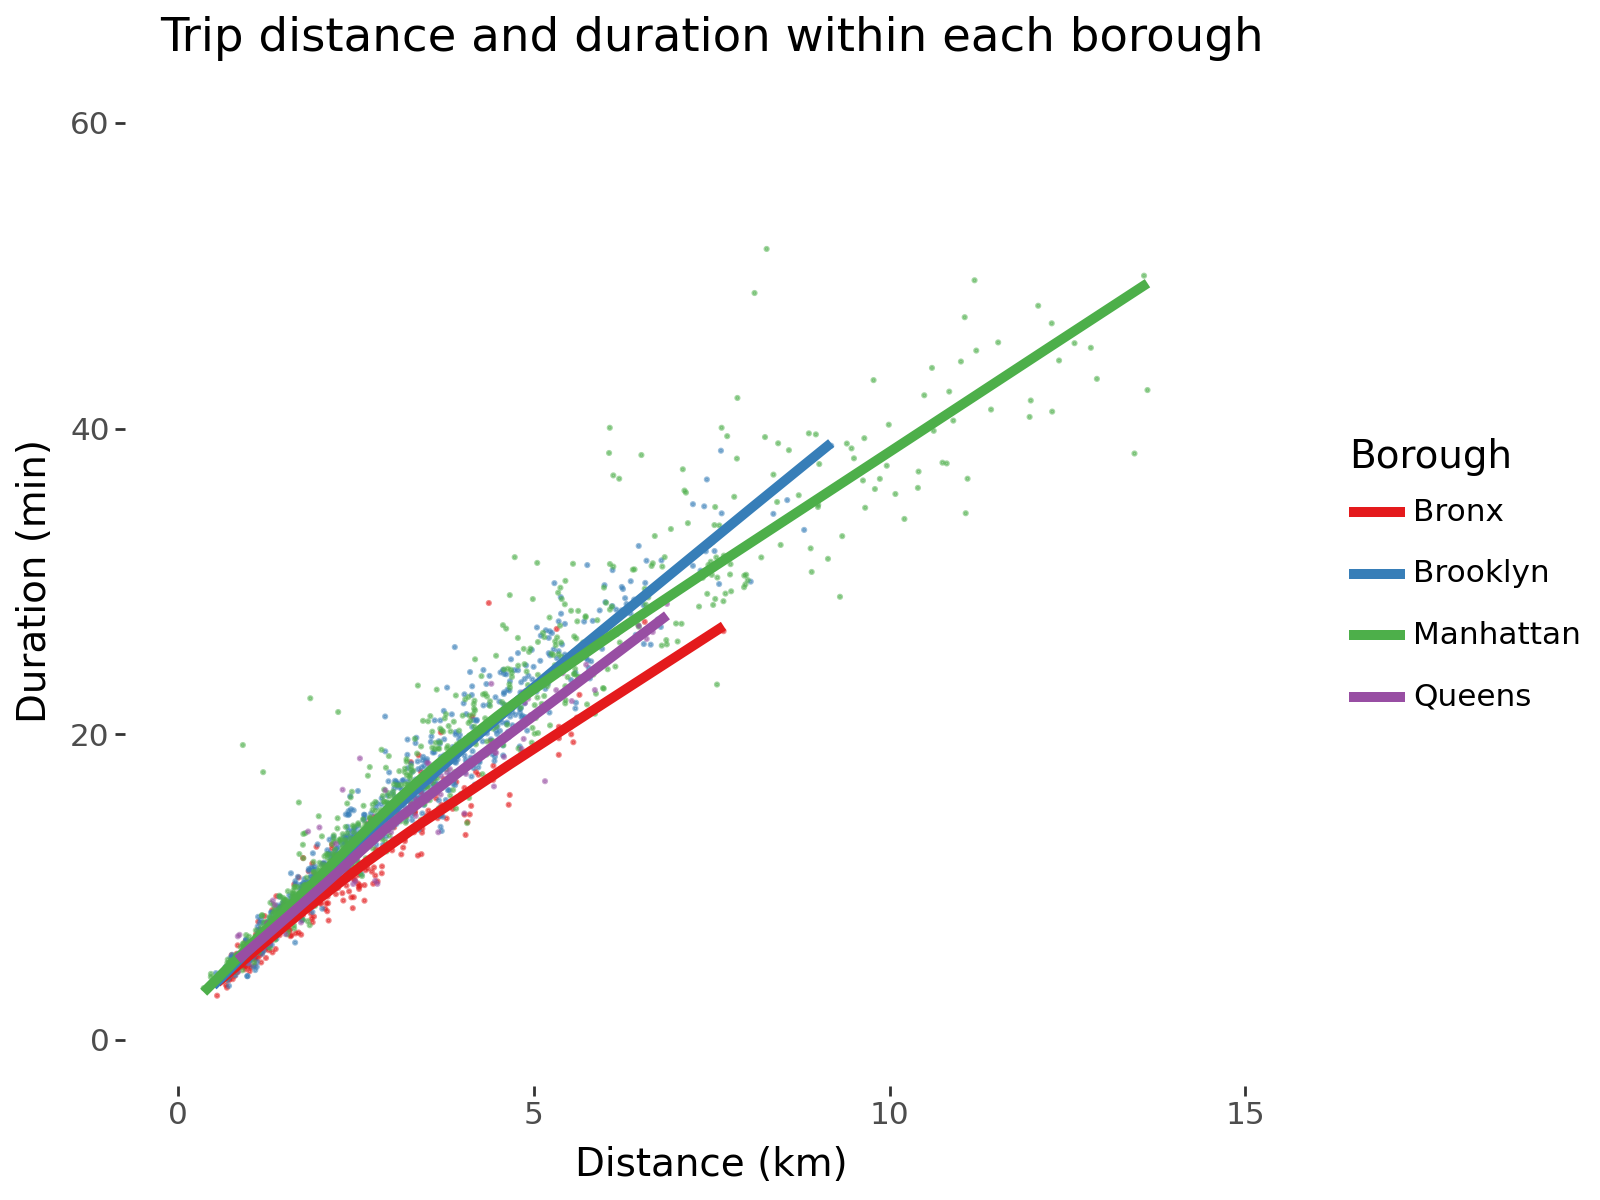

In [64]:
(
    ggplot(
        data=trips_speed.filter(
            pl.col("borough_start") == pl.col("borough_end")
        ),
        mapping=aes(x="distance", y="duration", color="borough_end"),
    )
    + geom_point(size=0.25, alpha=0.5)
    + geom_smooth(method="lowess", size=2, se=False, alpha=0.8)
    + xlim(0, 15)
    + ylim(0, 60)
    + scale_color_brewer(type="qualitative", palette="Set1")
    + labs(
        title="Trip distance and duration within each borough",
        x="Distance (km)",
        y="Duration (min)",
        color="Borough",
    )
    + theme_tufte(base_size=14)
    + theme(
        figure_size=(8, 6),
        plot_background=element_rect(color="#ffffff"),
    )
)

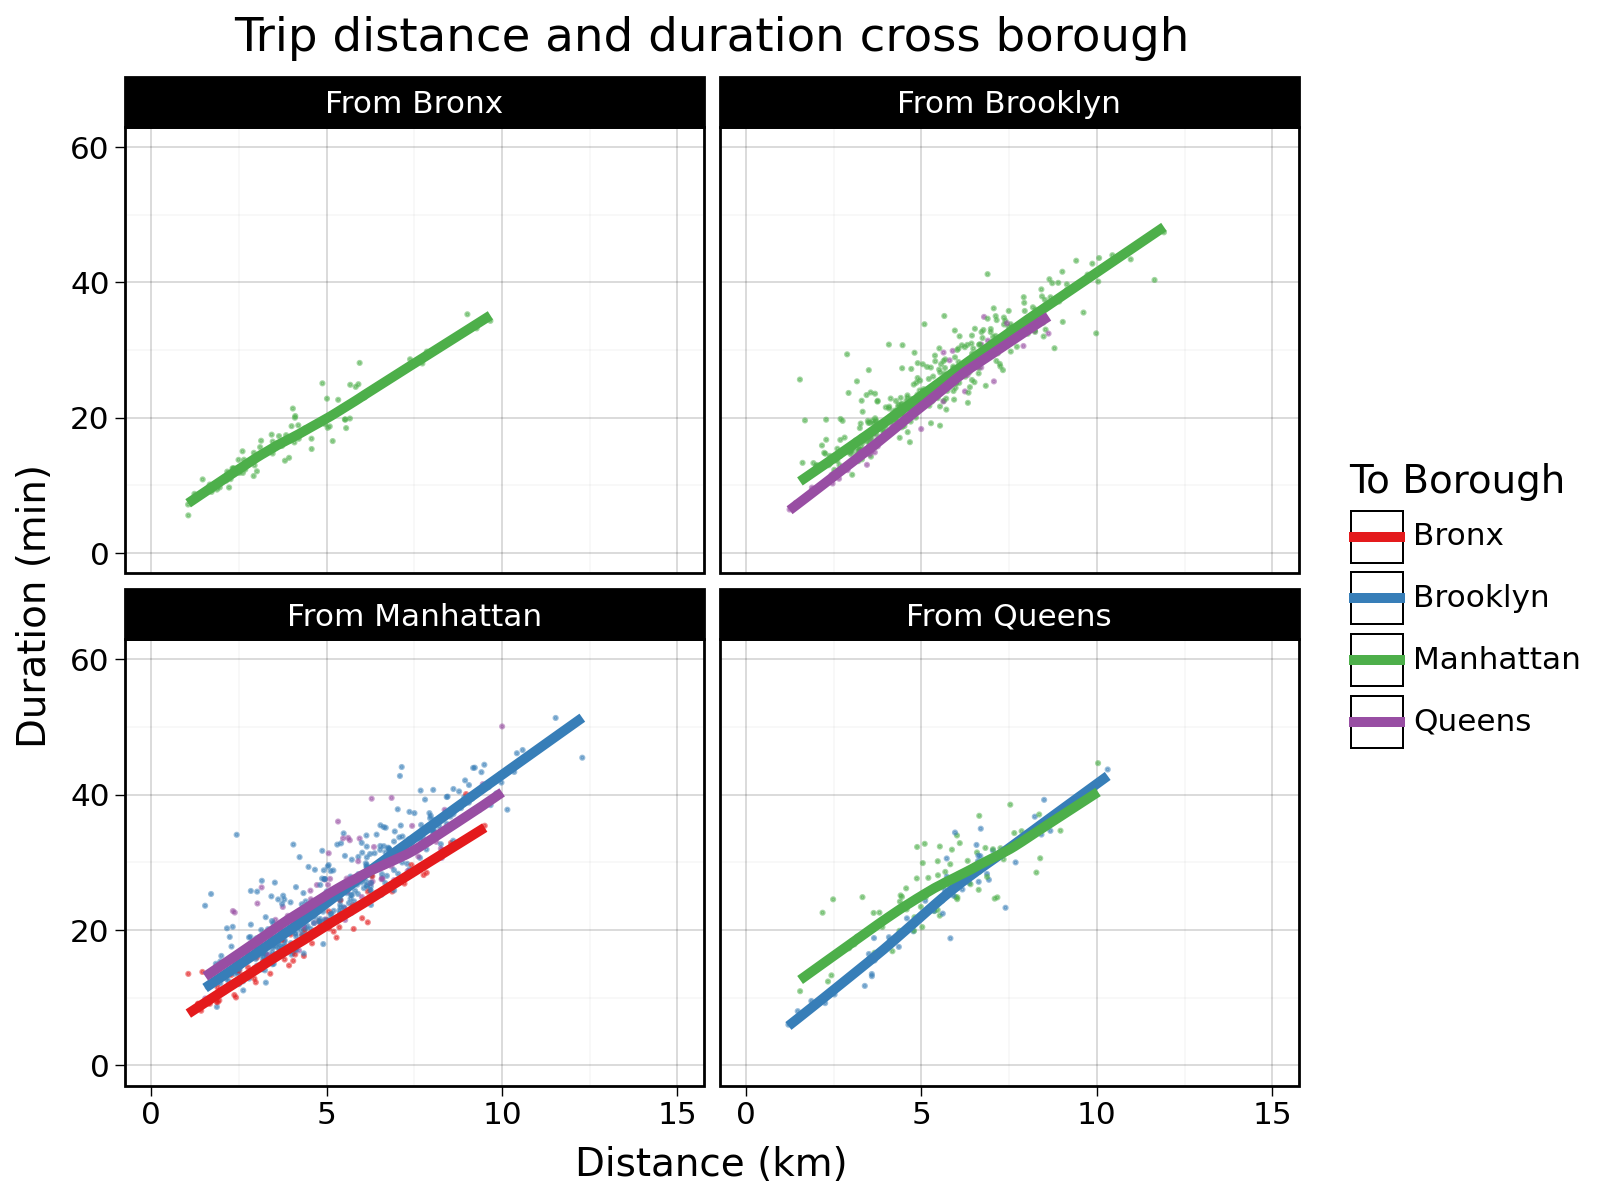

In [65]:
(
    ggplot(
        data=trips_speed.filter(
            pl.col("borough_start") != pl.col("borough_end")
        ).with_columns(
            ("From " + pl.col("borough_start")).alias("borough_start")
        ),
        mapping=aes(x="distance", y="duration", color="borough_end"),
    )
    + geom_point(size=0.25, alpha=0.5)
    + geom_smooth(method="lowess", size=2, se=False, alpha=0.8)
    + xlim(0, 15)
    + ylim(0, 60)
    + scale_color_brewer(type="qualitative", palette="Set1")
    + facet_wrap("borough_start")
    + labs(
        title="Trip distance and duration cross borough",
        x="Distance (km)",
        y="Duration (min)",
        color="To Borough",
    )
    + theme_linedraw(base_size=14)
    + theme(figure_size=(8, 6))
)

## Styling DataFrames With Great Tables

In [66]:
import polars.selectors as cs

busiest_stations = (
    trips.group_by(
        station=pl.col("station_start"), date=pl.col("datetime_start").dt.date()
    )
    .agg(
        borough=pl.col("borough_start").first(),
        neighborhood=pl.col("neighborhood_start").first(),
        num_rides=pl.len(),
        percent_member=(pl.col("rider_type") == "member").mean(),
        percent_electric=(pl.col("bike_type") == "electric").mean(),
    )
    .sort("date")
    .group_by("station")
    .agg(
        cs.string().first(),
        cs.numeric().mean(),
        pl.col("num_rides").alias("rides_per_day"),
    )
    .sort("num_rides", descending=True)
    .group_by("borough", maintain_order=True)
    .head(3)
)

busiest_stations

borough,station,neighborhood,num_rides,percent_member,percent_electric,rides_per_day
str,str,str,f64,f64,f64,list[u32]
"""Manhattan""","""W 21 St & 6 Ave""","""Chelsea""",354.16129,0.913765,0.583606,"[325, 88, … 306]"
"""Manhattan""","""Broadway & W 58 St""","""Midtown""",307.548387,0.796369,0.705783,"[222, 65, … 365]"
"""Manhattan""","""8 Ave & W 31 St""","""Chelsea""",288.258065,0.865356,0.640417,"[279, 86, … 286]"
"""Brooklyn""","""Metropolitan Ave & Bedford Ave""","""Williamsburg""",184.870968,0.854857,0.679675,"[173, 59, … 241]"
"""Brooklyn""","""N 7 St & Driggs Ave""","""Williamsburg""",145.709677,0.860029,0.655534,"[134, 51, … 147]"
…,…,…,…,…,…,…
"""Queens""","""Vernon Blvd & 50 Ave""","""Long Island City""",95.16129,0.890379,0.663037,"[94, 28, … 122]"
"""Queens""","""31 St & Newtown Ave""","""Astoria""",78.16129,0.883093,0.596819,"[77, 29, … 61]"
"""Bronx""","""Melrose Ave & E 150 St""","""Melrose""",41.612903,0.834158,0.894699,"[43, 15, … 38]"


In [68]:
%pip install great_tables

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 20.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 607.2/607.2 kB 20.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [great_tables]


In [69]:
from great_tables import GT

In [70]:
GT(busiest_stations)

borough,station,neighborhood,num_rides,percent_member,percent_electric,rides_per_day
Manhattan,W 21 St & 6 Ave,Chelsea,354.16129032258067,0.9137649488411791,0.5836060628339382,"[325, 88, 409, 433, 221, 219, 365, 369, 162, 307, 378, 502, 507, 498, 447, 415, 361, 385, 385, 361, 369, 366, 91, 370, 446, 480, 407, 210, 428, 369, 306]"
Manhattan,Broadway & W 58 St,Midtown,307.5483870967742,0.7963690113856158,0.7057834322293212,"[222, 65, 446, 299, 122, 154, 340, 332, 122, 171, 278, 373, 359, 433, 660, 766, 662, 267, 281, 284, 243, 237, 41, 210, 279, 304, 280, 172, 407, 360, 365]"
Manhattan,8 Ave & W 31 St,Chelsea,288.258064516129,0.8653562450153743,0.6404165834717459,"[279, 86, 245, 360, 166, 245, 322, 317, 92, 153, 317, 449, 421, 497, 406, 274, 277, 271, 395, 318, 350, 282, 62, 176, 347, 404, 336, 217, 344, 242, 286]"
Brooklyn,Metropolitan Ave & Bedford Ave,Williamsburg,184.8709677419355,0.8548570633632914,0.6796751094803254,"[173, 59, 231, 208, 114, 97, 216, 240, 88, 134, 172, 244, 247, 200, 219, 225, 269, 169, 158, 173, 176, 181, 88, 218, 211, 230, 180, 90, 224, 256, 241]"
Brooklyn,N 7 St & Driggs Ave,Williamsburg,145.70967741935485,0.8600288134761425,0.655533737720296,"[134, 51, 183, 117, 98, 86, 149, 176, 71, 99, 142, 168, 191, 202, 183, 235, 171, 145, 172, 183, 152, 162, 35, 98, 151, 189, 172, 107, 169, 179, 147]"
Brooklyn,Hanson Pl & Ashland Pl,Fort Greene,143.83870967741936,0.8361605984376713,0.6139227831846855,"[145, 46, 133, 158, 105, 111, 148, 178, 50, 86, 163, 155, 191, 224, 230, 171, 161, 155, 177, 152, 148, 156, 29, 103, 150, 186, 165, 108, 168, 149, 158]"
Queens,Queens Plaza North & Crescent St,Long Island City,126.74193548387096,0.8537365542705813,0.5707317493983467,"[89, 34, 188, 160, 55, 61, 118, 138, 80, 115, 135, 195, 181, 203, 196, 220, 167, 133, 113, 100, 104, 103, 28, 91, 137, 163, 109, 71, 150, 159, 133]"
Queens,Vernon Blvd & 50 Ave,Long Island City,95.16129032258064,0.8903794246434367,0.6630370994599845,"[94, 28, 96, 102, 56, 58, 100, 95, 26, 34, 85, 120, 124, 124, 102, 46, 56, 109, 112, 88, 115, 132, 39, 103, 155, 152, 121, 113, 121, 122, 122]"
Queens,31 St & Newtown Ave,Astoria,78.16129032258064,0.8830932418797898,0.5968191831951198,"[77, 29, 80, 96, 43, 57, 84, 88, 36, 54, 98, 110, 103, 109, 107, 62, 65, 112, 93, 92, 79, 86, 34, 70, 90, 93, 95, 53, 83, 84, 61]"
Bronx,Melrose Ave & E 150 St,Melrose,41.61290322580645,0.8341575787497404,0.8946989054437854,"[43, 15, 36, 54, 39, 24, 63, 58, 24, 32, 38, 45, 68, 59, 73, 37, 39, 47, 43, 41, 45, 41, 10, 29, 43, 49, 47, 34, 48, 28, 38]"


In [71]:
from great_tables import style, md

(
    GT(busiest_stations)
    .tab_stub(rowname_col="station", groupname_col="borough")
    .cols_label(
        neighborhood="Neighborhood",
        num_rides="Mean Daily Rides",
        percent_member="Members",
        percent_electric="E-Bikes",
        rides_per_day="Rides Per Day",
    )
    .tab_header(
        title="Busiest Bike Stations in NYC",
        subtitle="In March 2024, Per Borough",
    )
    .tab_stubhead(label="Station")
    .fmt_number(columns="num_rides", decimals=1)
    .fmt_percent(columns=cs.starts_with("percent_"), decimals=0)
    .fmt_nanoplot(columns="rides_per_day", reference_line="mean")
    .data_color(columns="num_rides", palette="Blues")
    .tab_options(row_group_font_weight="bold")
    .tab_source_note(
        source_note=md(
            "Source: [NYC Citi Bike](https://citibikenyc.com/system-data)"
        )
    )
)

GT(_tbl_data=shape: (12, 7)
┌───────────┬──────────────┬──────────────┬────────────┬──────────────┬──────────────┬─────────────┐
│ borough   ┆ station      ┆ neighborhood ┆ num_rides  ┆ percent_memb ┆ percent_elec ┆ rides_per_d │
│ ---       ┆ ---          ┆ ---          ┆ ---        ┆ er           ┆ tric         ┆ ay          │
│ str       ┆ str          ┆ str          ┆ f64        ┆ ---          ┆ ---          ┆ ---         │
│           ┆              ┆              ┆            ┆ f64          ┆ f64          ┆ list[u32]   │
╞═══════════╪══════════════╪══════════════╪════════════╪══════════════╪══════════════╪═════════════╡
│ Manhattan ┆ W 21 St & 6  ┆ Chelsea      ┆ 354.16129  ┆ 0.913765     ┆ 0.583606     ┆ [325, 88, … │
│           ┆ Ave          ┆              ┆            ┆              ┆              ┆ 306]        │
│ Manhattan ┆ Broadway & W ┆ Midtown      ┆ 307.548387 ┆ 0.796369     ┆ 0.705783     ┆ [222, 65, … │
│           ┆ 58 St        ┆              ┆            ┆              ┆              ┆ 365]        │
│ Manhattan ┆ 8 Ave & W 31 ┆ Chelsea      ┆ 288.258065 ┆ 0.865356     ┆ 0.640417     ┆ [279, 86, … │
│           ┆ St           ┆              ┆            ┆              ┆              ┆ 286]        │
│ Brooklyn  ┆ Metropolitan ┆ Williamsburg ┆ 184.870968 ┆ 0.854857     ┆ 0.679675     ┆ [173, 59, … │
│           ┆ Ave &        ┆              ┆            ┆              ┆              ┆ 241]        │
│           ┆ Bedford Ave  ┆              ┆            ┆              ┆              ┆             │
│ Brooklyn  ┆ N 7 St &     ┆ Williamsburg ┆ 145.709677 ┆ 0.860029     ┆ 0.655534     ┆ [134, 51, … │
│           ┆ Driggs Ave   ┆              ┆            ┆              ┆              ┆ 147]        │
│ …         ┆ …            ┆ …            ┆ …          ┆ …            ┆ …            ┆ …           │
│ Queens    ┆ Vernon Blvd  ┆ Long Island  ┆ 95.16129   ┆ 0.890379     ┆ 0.663037     ┆ [94, 28, …  │
│           ┆ & 50 Ave     ┆ City         ┆            ┆              ┆              ┆ 122]        │
│ Queens    ┆ 31 St &      ┆ Astoria      ┆ 78.16129   ┆ 0.883093     ┆ 0.596819     ┆ [77, 29, …  │
│           ┆ Newtown Ave  ┆              ┆            ┆              ┆              ┆ 61]         │
│ Bronx     ┆ Melrose Ave  ┆ Melrose      ┆ 41.612903  ┆ 0.834158     ┆ 0.894699     ┆ [43, 15, …  │
│           ┆ & E 150 St   ┆              ┆            ┆              ┆              ┆ 38]         │
│ Bronx     ┆ E 161 St &   ┆ Concourse    ┆ 35.483871  ┆ 0.744404     ┆ 0.879168     ┆ [32, 12, …  │
│           ┆ River Ave    ┆              ┆            ┆              ┆              ┆ 50]         │
│ Bronx     ┆ Plaza Dr & W ┆ Mount Eden   ┆ 31.709677  ┆ 0.837427     ┆ 0.948925     ┆ [30, 19, …  │
│           ┆ 170 St       ┆              ┆            ┆              ┆              ┆ 33]         │
└───────────┴──────────────┴──────────────┴────────────┴──────────────┴──────────────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x7cc3b21983e0>, _boxhead=Boxhead([ColInfo(var='borough', type=<ColInfoTypeEnum.row_group: 3>, column_label='borough', column_align='left', column_width=None, stub_level=None), ColInfo(var='station', type=<ColInfoTypeEnum.stub: 2>, column_label='station', column_align='left', column_width=None, stub_level=0), ColInfo(var='neighborhood', type=<ColInfoTypeEnum.default: 1>, column_label='Neighborhood', column_align='left', column_width=None, stub_level=None), ColInfo(var='num_rides', type=<ColInfoTypeEnum.default: 1>, column_label='Mean Daily Rides', column_align='right', column_width=None, stub_level=None), ColInfo(var='percent_member', type=<ColInfoTypeEnum.default: 1>, column_label='Members', column_align='right', column_width=None, stub_level=None), ColInfo(var='percent_electric', type=<ColInfoTypeEnum.default: 1>, column_label='E-Bikes', column_align='right', column_width=None, stub_level=None), ColInfo(var='rides_per_day', type=<ColInfoTypeEnum.default: 1>, column_label='Rides Per

## Takeaways